# Using pre-trained models from keras.applications

In [26]:
import tensorflow as tf
import tensorflow.keras as keras

from tensorflow.keras.preprocessing import image


import numpy as np
import matplotlib.pyplot as plt
import os

## Pick a model:

You can see all models available in `keras.applications` [on this page](https://keras.io/api/applications/#available-models).

Try other models such as:
- InceptionV3
- MobileNetV2


In [27]:
from tensorflow.keras.applications import resnet50
from tensorflow.keras.applications.resnet50 import ResNet50

model = ResNet50(weights='imagenet')

You can use `model.summary` and `keras.utils.plot_model` to help you visualize the architecture of the model you are using.

Note how many trainable parameters the model has. Compare this quantity between models.

In [28]:
model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)



In [29]:
keras.utils.plot_model(model)

## Donwload an image to be classified
**Donwload an image (PNG or JPEG) into the current directory and write its path to `img_path`.**

The example bellow used the image from https://a-z-animals.com/media/Chihuahua-Canis-familiaris-puppies-600x400.jpg

In [33]:
# img_path = 'path/to/my/image'
img_path = '/content/Chihuahua-Canis-familiaris-puppies-600x400.jpg'

**Note** You may need to adapt the image size (`target_size` parameter) to the shape expected by the model you are using.

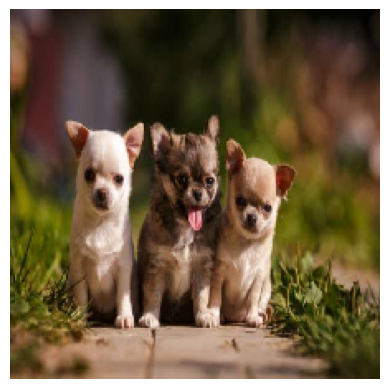

In [34]:
img = image.load_img(img_path, target_size=(224, 224))
plt.imshow(img)
plt.axis('off');

## Preprocessing image
The image needs to have 4 dimensions. The first one correspond to the array of images submitted to the model (the batch). The second and third correspond to the height and width of the image, while the third corresponds to the color channels (red, green and blue).

**Attention** In some models/libraries the convention is to have the channels dimension first, before height and width. You can also set keras to follow this convention if needed.

Moreover, each model was trained expecting a specific input size, as well as specific pixel normalizations applied to the image. The function `preprocess_input` takes all into account and preprocess the image accordingly.

In [35]:
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = resnet50.preprocess_input(x)

## Computing predictions
You can use `model.predict` to compute predictions for an array X as you would do to a custom created model. Each model may have associated functions to decode its output into probability predictions: it is the case for ResNet-50 with the `resnet50.decode_predictions`.

In [36]:
preds = model.predict(x)
# decode the results into a list of tuples (class, description, probability)
# (one such list for each sample in the batch)
print('Predicted:', resnet50.decode_predictions(preds, top=3)[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Predicted: [('n02085620', 'Chihuahua', np.float32(0.9810347)), ('n02441942', 'weasel', np.float32(0.003967634)), ('n02109961', 'Eskimo_dog', np.float32(0.0023844782))]
